# 01 · Exploratory Data Analysis & Data-Quality Audit

> **A reproducible audit of TMDB 5000’s schema, reported financials, target proxies, distributions, and selection effects.**

This notebook defines the *reported-financials analysis population* and separates observations supported by the files from assumptions that need external validation. The $10,000 threshold is shown only as a sensitivity scenario; it is not used to label records as corrupted or to define the primary population.

## 1. Environment, source files & relational integrity

The source files contain 20 movie columns and 4 credits columns. `movie_id` repeats the `id` key and credits `title` repeats movie `title`; we verify the one-to-one keys and title agreement before dropping these redundant fields. The expected merged schema is 22 unique columns.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import (
    get_default_data_paths,
    load_and_merge_data,
    filter_reported_financials,
    filter_minimum_scale,
)

sns.set_theme(style='whitegrid', context='notebook')
mpl.rcParams['figure.dpi'] = 110
mpl.rcParams['axes.titleweight'] = 'bold'
PALETTE = {'flop': '#ef4444', 'success': '#10b981'}
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 150)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

print(f'pandas {pd.__version__} · numpy {np.__version__} · matplotlib {mpl.__version__} · seaborn {sns.__version__}')
movies_path, credits_path = get_default_data_paths()
movies = pd.read_csv(movies_path)
credits = pd.read_csv(credits_path)
print(f'Movies: {movies.shape[0]:,} rows × {movies.shape[1]} columns')
print(f'Credits: {credits.shape[0]:,} rows × {credits.shape[1]} columns')
print(f'Unique source columns after key/title deduplication: {movies.shape[1] + credits.shape[1] - 2}')

df_raw = load_and_merge_data()
assert df_raw.shape == (4_803, 22), f'Unexpected merged shape: {df_raw.shape}'
assert movies['id'].is_unique and credits['movie_id'].is_unique
assert (movies.merge(credits, left_on='id', right_on='movie_id').title_x ==
        movies.merge(credits, left_on='id', right_on='movie_id').title_y).all()
print(f'Validated one-to-one merge: {len(df_raw):,} rows × {df_raw.shape[1]} unique columns.')
df_raw.head(3)

pandas 3.0.6 · numpy 2.5.4 · matplotlib 3.11.2 · seaborn 0.13.2


Movies: 4,803 rows × 20 columns
Credits: 4,803 rows × 4 columns
Unique source columns after key/title deduplication: 22


Validated one-to-one merge: 4,803 rows × 22 unique columns.


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count,cast,crew
0,4000000,"[{""id"": 80, ""name"": ""Crime""}, {""id"": 35, ""name...",NaN,5,"[{""id"": 612, ""name"": ""hotel""}, {""id"": 613, ""na...",en,Four Rooms,It's Ted the Bellhop's first night on the job....,22.88,"[{""name"": ""Miramax Films"", ""id"": 14}, {""name"":...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",1995-12-09,4300000,98.00,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,Twelve outrageous guests. Four scandalous requ...,Four Rooms,6.50,530,"[{""cast_id"": 42, ""character"": ""Ted the Bellhop...","[{""credit_id"": ""52fe420dc3a36847f800012d"", ""de..."
1,11000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 28, ""...",http://www.starwars.com/films/star-wars-episod...,11,"[{""id"": 803, ""name"": ""android""}, {""id"": 4270, ...",en,Star Wars,Princess Leia is captured and held hostage by ...,126.39,"[{""name"": ""Lucasfilm"", ""id"": 1}, {""name"": ""Twe...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",1977-05-25,775398007,121.00,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"A long time ago in a galaxy far, far away...",Star Wars,8.10,6624,"[{""cast_id"": 3, ""character"": ""Luke Skywalker"",...","[{""credit_id"": ""52fe420dc3a36847f8000437"", ""de..."
2,94000000,"[{""id"": 16, ""name"": ""Animation""}, {""id"": 10751...",http://movies.disney.com/finding-nemo,12,"[{""id"": 494, ""name"": ""father son relationship""...",en,Finding Nemo,"Nemo, an adventurous young clownfish, is unexp...",85.69,"[{""name"": ""Pixar Animation Studios"", ""id"": 3}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2003-05-30,940335536,100.00,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"There are 3.7 trillion fish in the ocean, they...",Finding Nemo,7.60,6122,"[{""cast_id"": 8, ""character"": ""Marlin (voice)"",...","[{""credit_id"": ""52fe420ec3a36847f80006b1"", ""de..."


## 2. Missingness and zero audit

The CSV encodes many unavailable financial values as zero. We report zeros, explicit missing values, and non-finite values separately; they are not interchangeable. A positive reported budget and revenue define the primary *observed reported-financials subset*, not “all theatrical films” and not a random sample of all movies.

In [2]:
n_raw = len(df_raw)
financial_audit = []
for col in ['budget', 'revenue']:
    values = pd.to_numeric(df_raw[col], errors='coerce')
    financial_audit.append({
        'Column': col,
        'Zero': int(values.eq(0).sum()),
        'NaN / unparsable': int(values.isna().sum()),
        'Negative': int(values.lt(0).sum()),
        'Non-finite': int((~np.isfinite(values.dropna())).sum()),
        'Positive finite': int((values.gt(0) & np.isfinite(values)).sum()),
    })
financial_audit = pd.DataFrame(financial_audit).set_index('Column')
financial_audit

,Zero,NaN / unparsable,Negative,Non-finite,Positive finite
Column,,,,,
budget,1037,0,0,0,3766
revenue,1427,0,0,0,3376


In [3]:
df_reported = filter_reported_financials(df_raw)
missing_or_nonpositive = len(df_raw) - len(df_reported)
print('Primary population rule: budget > 0 and revenue > 0, both finite.')
print(f'{len(df_raw):,} raw rows − {missing_or_nonpositive:,} excluded = {len(df_reported):,} rows with reported positive financials.')
print('This rule does not establish release channel or commercial failure for excluded rows.')
print('Status values among retained rows:')
df_reported['status'].value_counts(dropna=False).to_frame('rows')

Primary population rule: budget > 0 and revenue > 0, both finite.
4,803 raw rows − 1,574 excluded = 3,229 rows with reported positive financials.
This rule does not establish release channel or commercial failure for excluded rows.
Status values among retained rows:


,rows
status,
Released,3228
Post Production,1


**Selection limitation:** the retained sample is selected by *financial reporting*. Missing financials may be related to release scale or commercial outcome, but these files alone cannot identify why a value is zero or missing. Claims about survivorship bias should therefore be framed as a plausible selection concern, not proof that every excluded film failed or lacked theatrical distribution.

## 3. $10,000 threshold as sensitivity analysis—not an anomaly detector

A strict `budget > $10,000 AND revenue > $10,000` rule removes 26 rows from the 3,229-row reported-financials set. The threshold is a policy choice; these files do not prove that all below-threshold values are scale errors. We keep the reported-financials population primary and show the threshold subset only to measure how this choice changes the sample.

In [4]:
df_floor_sensitivity = filter_minimum_scale(df_reported, usd_floor=10_000)
under_floor = df_reported.loc[~df_reported.index.isin(df_floor_sensitivity.index)].copy()
under_floor['nominal_gross_proxy'] = np.where(
    under_floor['revenue'] > under_floor['budget'], 'Revenue > budget', 'Revenue <= budget'
)
print(f'Optional strict >$10K sensitivity subset: {len(df_floor_sensitivity):,} rows.')
print(f'Below/equal-floor rows removed by this policy: {len(under_floor):,}; '
      f'{int((under_floor["nominal_gross_proxy"] == "Revenue > budget").sum())} nominal gross-above-budget and '
      f'{int((under_floor["nominal_gross_proxy"] == "Revenue <= budget").sum())} nominal gross-at/below-budget.')
under_floor[['title', 'budget', 'revenue', 'release_date', 'nominal_gross_proxy']].sort_values('budget').reset_index(drop=True)

Optional strict >$10K sensitivity subset: 3,203 rows.
Below/equal-floor rows removed by this policy: 26; 10 nominal gross-above-budget and 16 nominal gross-at/below-budget.


,title,budget,revenue,release_date,nominal_gross_proxy
0,Modern Times,1,8500000,1936-02-05,Revenue > budget
1,A Farewell to Arms,4,25,1932-12-08,Revenue > budget
2,Split Second,7,5,1992-05-01,Revenue <= budget
3,Bran Nue Dae,7,7,2009-08-09,Revenue <= budget
4,The Prophecy,8,16,1995-09-01,Revenue > budget
5,Nurse 3-D,10,10000000,2013-09-28,Revenue > budget
6,Of Horses and Men,10,11,2013-08-30,Revenue > budget
7,F.I.S.T.,11,11,1978-04-26,Revenue <= budget
8,Angela's Ashes,25,13,1999-12-25,Revenue <= budget
9,The 51st State,28,14,2001-12-07,Revenue <= budget


**Interpretation rule:** do not call the entire table “currency corruption.” It mixes low budgets, low revenues, and boundary values. For example, records such as *Primer* ($7,000 budget), *Tarnation* ($218), and *Eraserhead* (exactly $10,000) require source-level verification before being called erroneous. If the threshold is retained for a later model, describe it as an explicitly chosen scale restriction and report results both with and without it.

## 4. Two revenue-multiple target proxies

We compare two *labels derived from reported gross and production budget*. Neither is ground-truth studio profit: the files do not provide exhibitor settlements, marketing/distribution spend, or other recoupable costs.

1. **Nominal gross proxy:** `revenue > budget`.
2. **2× gross-multiple proxy:** `revenue >= 2 × budget`, a rough sensitivity target motivated by box-office splits and excluded marketing costs—not a verified break-even label.

Because the inequality boundary is a convention, the receipt below also reports the strict `>` variant of the 2× rule so the two documented figures (55.87% vs 56.02% on the primary population) are not conflated.

In [5]:
def target_receipt(df: pd.DataFrame) -> pd.Series:
    nominal = df['target_nominal'].astype(bool)
    hollywood_ge = df['target_hollywood'].astype(bool)
    hollywood_gt = (df['revenue'] > 2.0 * df['budget'])
    return pd.Series({
        'Rows': f'{len(df):,}',
        'Revenue > budget proxy': f'{nominal.sum():,} ({nominal.mean() * 100:.2f}%)',
        'Revenue <= budget proxy': f'{(~nominal).sum():,} ({(~nominal).mean() * 100:.2f}%)',
        'Revenue >= 2x budget proxy': f'{hollywood_ge.sum():,} ({hollywood_ge.mean() * 100:.2f}%)',
        'Revenue > 2x budget proxy (strict)': f'{hollywood_gt.sum():,} ({hollywood_gt.mean() * 100:.2f}%)',
    })

target_receipts = pd.DataFrame({
    'Primary: reported finances': target_receipt(df_reported),
    'Sensitivity: both values > $10K': target_receipt(df_floor_sensitivity),
})
target_receipts.index.name = 'Target receipt'
target_receipts

,Primary: reported finances,Sensitivity: both values > $10K
Target receipt,,
Rows,"3,229","3,203"
Revenue > budget proxy,"2,438 (75.50%)","2,428 (75.80%)"
Revenue <= budget proxy,791 (24.50%),775 (24.20%)
Revenue >= 2x budget proxy,"1,809 (56.02%)","1,800 (56.20%)"
Revenue > 2x budget proxy (strict),"1,804 (55.87%)","1,796 (56.07%)"


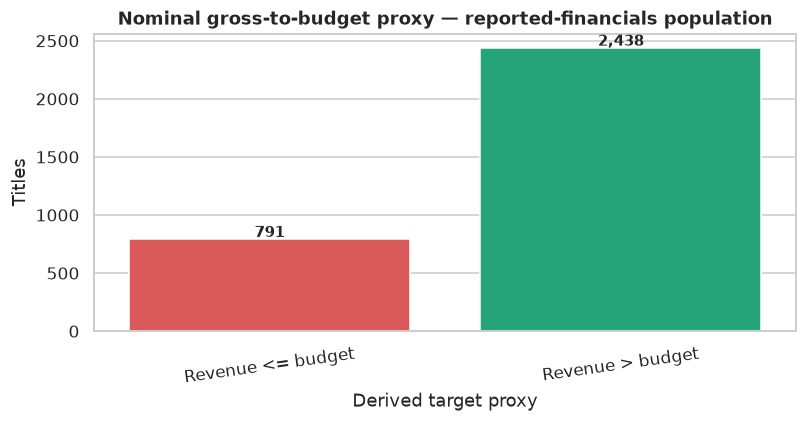

Majority-label accuracy baseline on this selected sample: 75.50%.
This is a class-prevalence baseline, not evidence of useful ranking or investment value.


In [6]:
nominal_counts = df_reported['target_nominal'].value_counts().reindex([0, 1], fill_value=0)
labels = df_reported['target_nominal'].map({0: 'Revenue <= budget', 1: 'Revenue > budget'})
fig, ax = plt.subplots(figsize=(7.5, 4))
sns.countplot(
    x=labels, hue=labels, order=['Revenue <= budget', 'Revenue > budget'],
    hue_order=['Revenue <= budget', 'Revenue > budget'],
    palette={'Revenue <= budget': PALETTE['flop'], 'Revenue > budget': PALETTE['success']},
    legend=False, ax=ax,
)
ax.set_title('Nominal gross-to-budget proxy — reported-financials population')
ax.set_xlabel('Derived target proxy'); ax.set_ylabel('Titles')
for i, count in enumerate([nominal_counts.get(0, 0), nominal_counts.get(1, 0)]):
    ax.text(i, count + 20, f'{count:,}', ha='center', fontsize=10, fontweight='bold')
plt.xticks(rotation=8)
plt.tight_layout(); plt.show()
print(f'Majority-label accuracy baseline on this selected sample: {nominal_counts.max() / len(df_reported) * 100:.2f}%.')
print('This is a class-prevalence baseline, not evidence of useful ranking or investment value.')

## 5. Financial distributions and concentration

Financial amounts are strongly right-skewed. We show raw and log1p views and report concentration as a descriptive property of this selected dataset. A log transform changes skew but does not guarantee a more symmetric feature distribution; compare it in both the primary and sensitivity populations.

                      Budget (USD)  Revenue (USD)
Statistic                                        
Mean                 40,654,444.77 121,242,957.26
Median               25,000,000.00  55,184,721.00
Std deviation        44,396,741.80 186,302,864.01
Skewness (raw scale)          2.09           3.82
Skewness (log1p)             -3.11          -2.35
                             Rows  Budget skew (raw)  Budget skew (log1p)  Revenue skew (raw)  Revenue skew (log1p)
Population                                                                                                         
Primary reported-financials  3229               2.09                -3.11                3.82                 -2.35
Optional >$10K sensitivity   3203               2.08                -1.10                3.81                 -1.13

Revenue concentration: top 5 titles = 2.34% of gross · top 20% of titles = 65.8% of gross


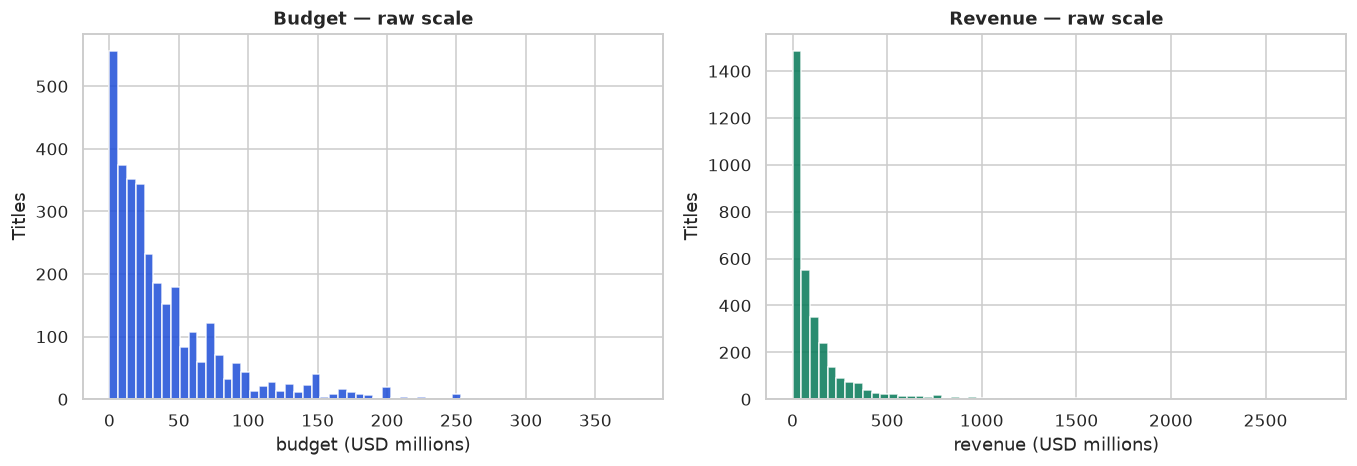

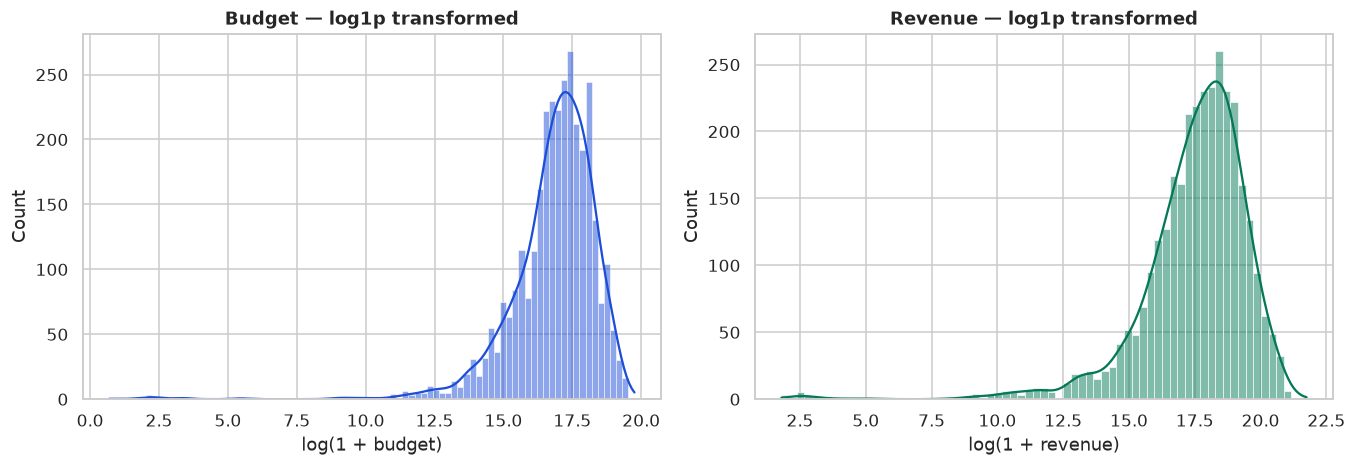

In [7]:
money = df_reported[['budget', 'revenue']]
skew_receipt = pd.DataFrame({
    'Statistic': ['Mean', 'Median', 'Std deviation', 'Skewness (raw scale)', 'Skewness (log1p)'],
    'Budget (USD)': [money['budget'].mean(), money['budget'].median(), money['budget'].std(),
                     money['budget'].skew(), np.log1p(money['budget']).skew()],
    'Revenue (USD)': [money['revenue'].mean(), money['revenue'].median(), money['revenue'].std(),
                      money['revenue'].skew(), np.log1p(money['revenue']).skew()],
}).set_index('Statistic')
print(skew_receipt.to_string())


def skew_summary(frame: pd.DataFrame, population: str) -> dict:
    return {
        'Population': population,
        'Rows': len(frame),
        'Budget skew (raw)': frame['budget'].skew(),
        'Budget skew (log1p)': np.log1p(frame['budget']).skew(),
        'Revenue skew (raw)': frame['revenue'].skew(),
        'Revenue skew (log1p)': np.log1p(frame['revenue']).skew(),
    }


# A log transform changes skew but does not guarantee symmetry; compare the
# primary population against the optional threshold sensitivity subset.
transform_skew = pd.DataFrame([
    skew_summary(df_reported, 'Primary reported-financials'),
    skew_summary(df_floor_sensitivity, 'Optional >$10K sensitivity'),
]).set_index('Population')
print(transform_skew.round(2).to_string())

top5_share = df_reported.nlargest(5, 'revenue')['revenue'].sum() / df_reported['revenue'].sum() * 100
top20pct_share = df_reported.nlargest(int(len(df_reported) * 0.2), 'revenue')['revenue'].sum() / df_reported['revenue'].sum() * 100
print(f'\nRevenue concentration: top 5 titles = {top5_share:.2f}% of gross · top 20% of titles = {top20pct_share:.1f}% of gross')

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
for ax, col, color in zip(axes, ['budget', 'revenue'], ['#1d4ed8', '#047857']):
    ax.hist(money[col] / 1e6, bins=60, color=color, alpha=.85)
    ax.set_title(f'{col.capitalize()} — raw scale')
    ax.set_xlabel(f'{col} (USD millions)'); ax.set_ylabel('Titles')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
for ax, col, color in zip(axes, ['budget', 'revenue'], ['#1d4ed8', '#047857']):
    sns.histplot(np.log1p(money[col]), kde=True, color=color, ax=ax)
    ax.set_title(f'{col.capitalize()} — log1p transformed')
    ax.set_xlabel(f'log(1 + {col})')
plt.tight_layout(); plt.show()


## 6. Runtime distribution

Report the raw nonzero-runtime median and the median in the primary reported-financials population separately. Runtime is a candidate predictor only if its value and availability can be established at the intended prediction time.

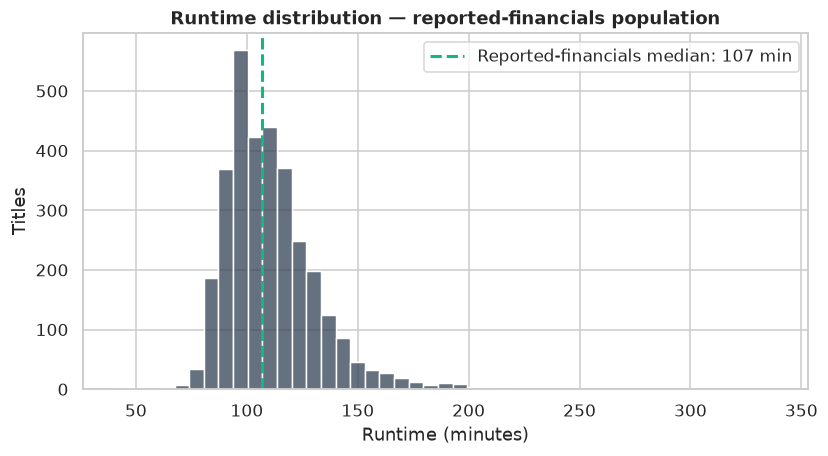

Raw sample, runtime > 0: median 104 min; NaN 2; zero 35.
Reported-financials subset: median 107 min; NaN 0; zero 0.


In [8]:
runtime_median_reported = df_reported['runtime'].median()
fig, ax = plt.subplots(figsize=(8.5, 4.2))
sns.histplot(df_reported['runtime'], bins=45, color='#334155', ax=ax)
ax.axvline(runtime_median_reported, color='#10b981', lw=2, ls='--',
           label=f'Reported-financials median: {runtime_median_reported:.0f} min')
ax.set_title('Runtime distribution — reported-financials population')
ax.set_xlabel('Runtime (minutes)'); ax.set_ylabel('Titles'); ax.legend()
plt.show()
rt_raw = df_raw['runtime'].dropna()
rt_raw = rt_raw[rt_raw > 0]
print(f'Raw sample, runtime > 0: median {rt_raw.median():.0f} min; '
      f'NaN {int(df_raw["runtime"].isna().sum())}; zero {int(df_raw["runtime"].eq(0).sum())}.')
print(f'Reported-financials subset: median {runtime_median_reported:.0f} min; '
      f'NaN {int(df_reported["runtime"].isna().sum())}; zero {int(df_reported["runtime"].eq(0).sum())}.')

## 7. Genre coverage

Genre lists are multi-label, not mutually exclusive. Counts below are title–genre memberships, so the totals across genres can exceed the number of titles. Empty or malformed lists are counted explicitly rather than silently interpreted as a real genre.

Titles with empty genre lists in reported-financials population: 1
Distinct genre labels: 19


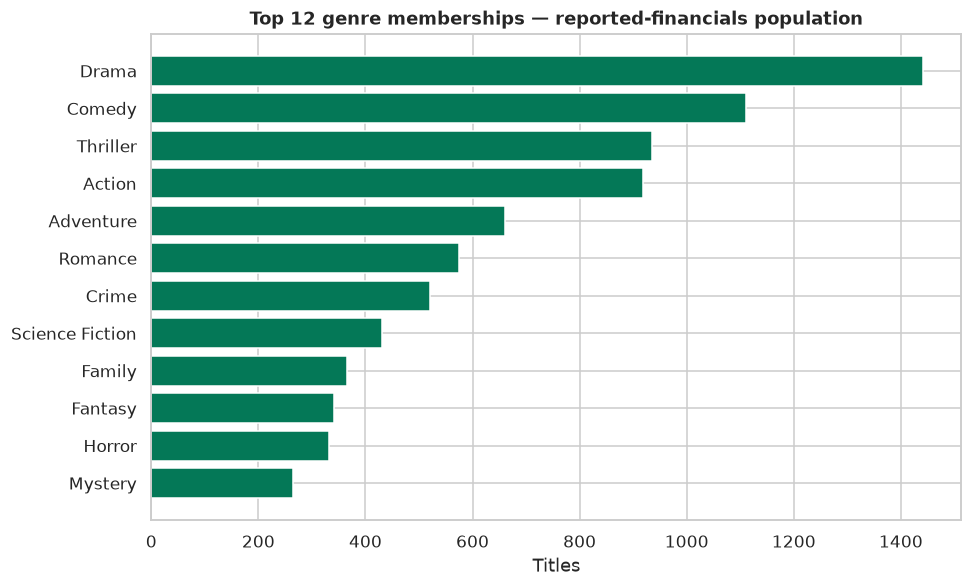

,titles
Drama,1441
Comedy,1110
Thriller,935
Action,918
Adventure,661
Romance,574
Crime,521
Science Fiction,431
Family,365
Fantasy,342


In [9]:
def parse_names(blob):
    try:
        return [entry['name'] for entry in json.loads(blob)]
    except (TypeError, ValueError):
        return []

genre_lists = df_reported['genres'].apply(parse_names)
genre_counts = pd.Series([g for lst in genre_lists for g in lst]).value_counts()
print(f'Titles with empty genre lists in reported-financials population: {int((genre_lists.str.len() == 0).sum())}')
print(f'Distinct genre labels: {genre_counts.size}')

top_genres = genre_counts.head(12)[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top_genres.index, top_genres.values, color='#047857')
ax.set_title('Top 12 genre memberships — reported-financials population')
ax.set_xlabel('Titles')
plt.tight_layout(); plt.show()
genre_counts.head(12).to_frame('titles')

## 8. Numeric associations and feature-availability audit

Pearson and Spearman coefficients describe association in the selected reported-financials sample. `popularity`, `vote_average`, and `vote_count` are leakage *candidates* for a pre-release task: classify them by their actual measurement timestamp and intended prediction date, not by their correlation with revenue. Raw Pearson correlations are also sensitive to skew and outliers.

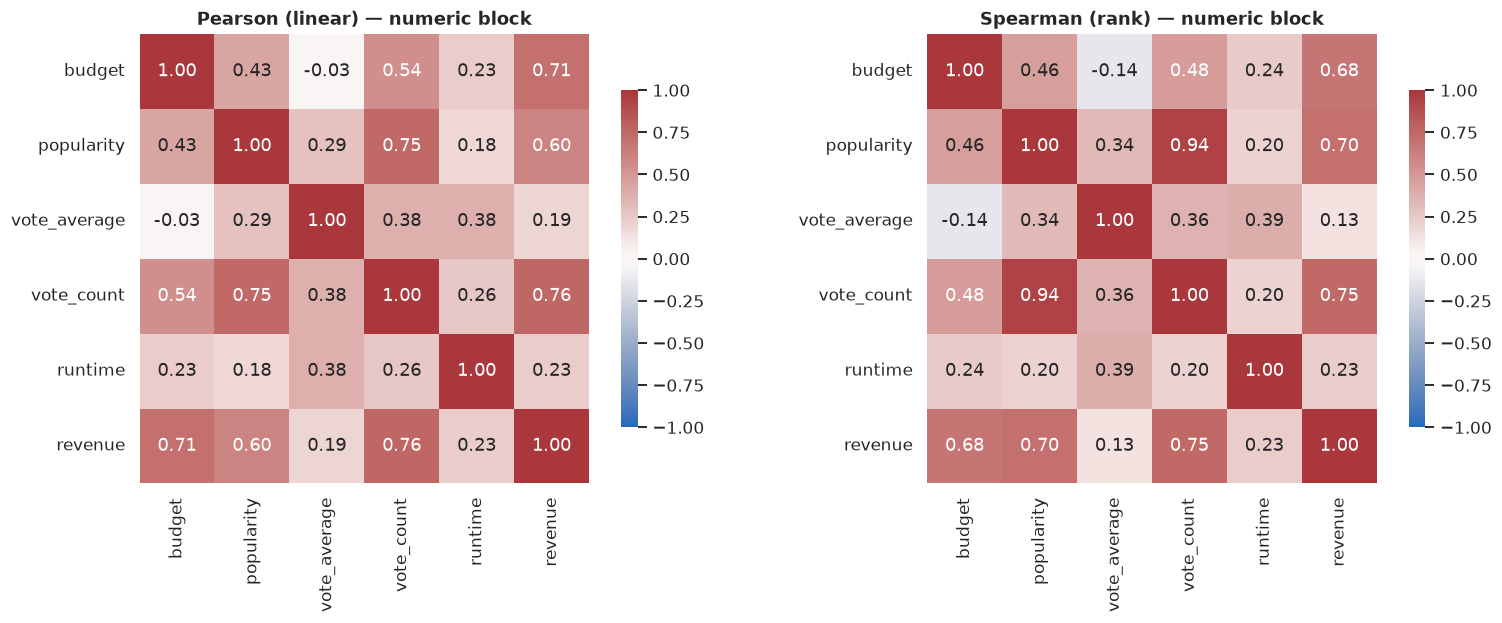

,Pearson ρ to revenue,Spearman ρ to revenue
vote_count,0.76,0.75
budget,0.71,0.68
popularity,0.60,0.70
runtime,0.23,0.23
vote_average,0.19,0.13


In [10]:
num_cols = ['budget', 'popularity', 'vote_average', 'vote_count', 'runtime', 'revenue']
pearson = df_reported[num_cols].corr()
spearman = df_reported[num_cols].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.6))
for ax, mat, method in zip(axes, [pearson, spearman], ['Pearson (linear)', 'Spearman (rank)']):
    sns.heatmap(mat, annot=True, fmt='.2f', cmap='vlag', center=0, vmin=-1, vmax=1,
                square=True, cbar_kws={'shrink': .75}, ax=ax)
    ax.set_title(f'{method} — numeric block')
plt.tight_layout(); plt.show()

leakage_receipt = pd.DataFrame({'Pearson ρ to revenue': pearson['revenue'],
                                'Spearman ρ to revenue': spearman['revenue']}).drop(index='revenue')
leakage_receipt.sort_values('Pearson ρ to revenue', ascending=False)

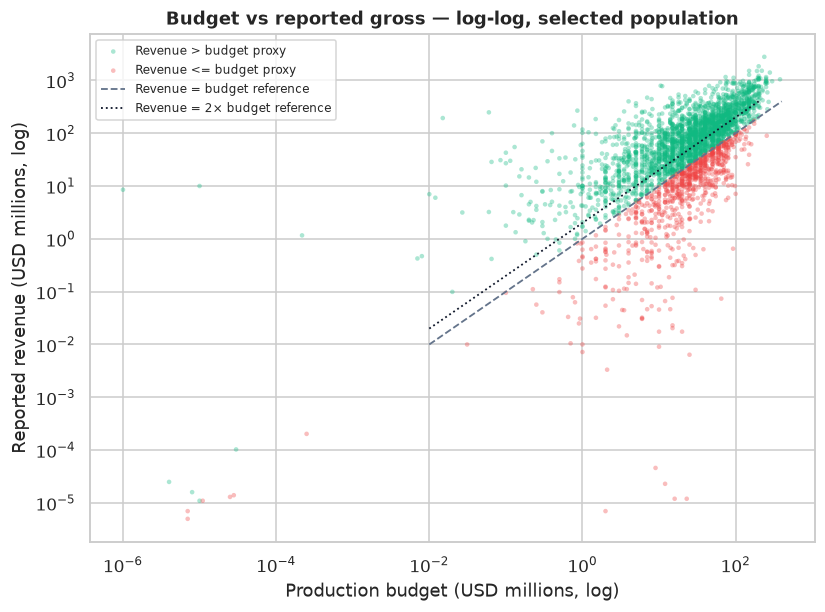

In [11]:
fig, ax = plt.subplots(figsize=(8.5, 6))
for label, color, name in [
    (1, PALETTE['success'], 'Revenue > budget proxy'),
    (0, PALETTE['flop'], 'Revenue <= budget proxy'),
]:
    subset = df_reported[df_reported['target_nominal'] == label]
    ax.scatter(subset['budget'] / 1e6, subset['revenue'] / 1e6, s=9, alpha=.35,
               color=color, label=name, edgecolors='none')
ax.plot([0.01, 400], [0.01, 400], color='#64748b', lw=1.2, ls='--',
        label='Revenue = budget reference')
ax.plot([0.01, 200], [0.02, 400], color='#0f172a', lw=1.2, ls=':',
        label='Revenue = 2× budget reference')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_title('Budget vs reported gross — log-log, selected population')
ax.set_xlabel('Production budget (USD millions, log)')
ax.set_ylabel('Reported revenue (USD millions, log)')
ax.legend(frameon=True, fontsize=8)
plt.show()

## 9. Calendar patterns — descriptive, not causal

Monthly release counts and revenue summaries combine films from many decades and budgets. The chart is descriptive: a month-level mean can be moved by blockbusters, and calendar patterns can be confounded by release-era trends. We show median revenue alongside the mean and avoid claiming a causal seasonal effect.

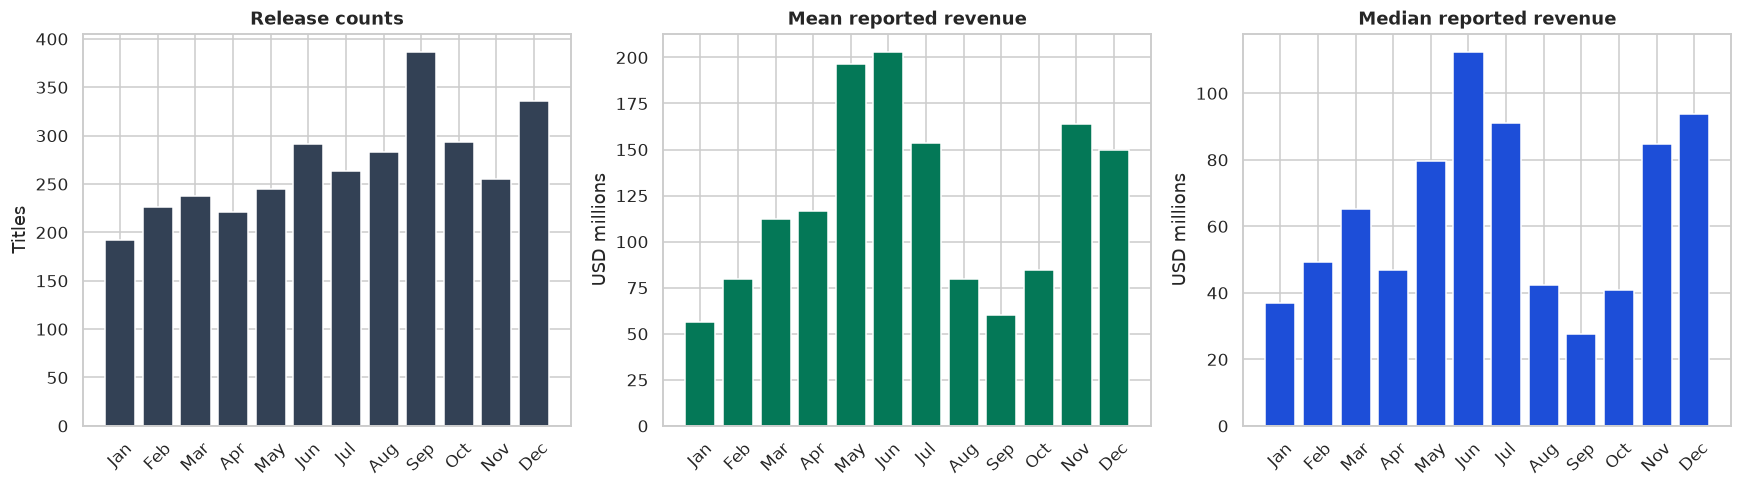

,releases,mean_revenue_millions,median_revenue_millions
Jan,192,56.42,36.80
Feb,226,79.60,49.40
Mar,238,112.10,65.12
Apr,221,116.63,46.91
May,245,196.39,79.70
Jun,291,202.71,112.27
Jul,263,153.39,91.19
Aug,283,79.83,42.28
Sep,386,60.30,27.53
Oct,293,84.75,40.85


In [12]:
temporal = df_reported.copy()
temporal['release_month'] = pd.to_datetime(temporal['release_date'], errors='coerce').dt.month
monthly = temporal.groupby('release_month').agg(
    releases=('title', 'count'),
    mean_revenue=('revenue', 'mean'),
    median_revenue=('revenue', 'median'),
)
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly.index = month_names
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
axes[0].bar(monthly.index, monthly['releases'], color='#334155')
axes[0].set_title('Release counts'); axes[0].set_ylabel('Titles')
axes[1].bar(monthly.index, monthly['mean_revenue'] / 1e6, color='#047857')
axes[1].set_title('Mean reported revenue'); axes[1].set_ylabel('USD millions')
axes[2].bar(monthly.index, monthly['median_revenue'] / 1e6, color='#1d4ed8')
axes[2].set_title('Median reported revenue'); axes[2].set_ylabel('USD millions')
for ax in axes: ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()
monthly.assign(
    mean_revenue_millions=monthly['mean_revenue'] / 1e6,
    median_revenue_millions=monthly['median_revenue'] / 1e6,
).drop(columns=['mean_revenue', 'median_revenue'])

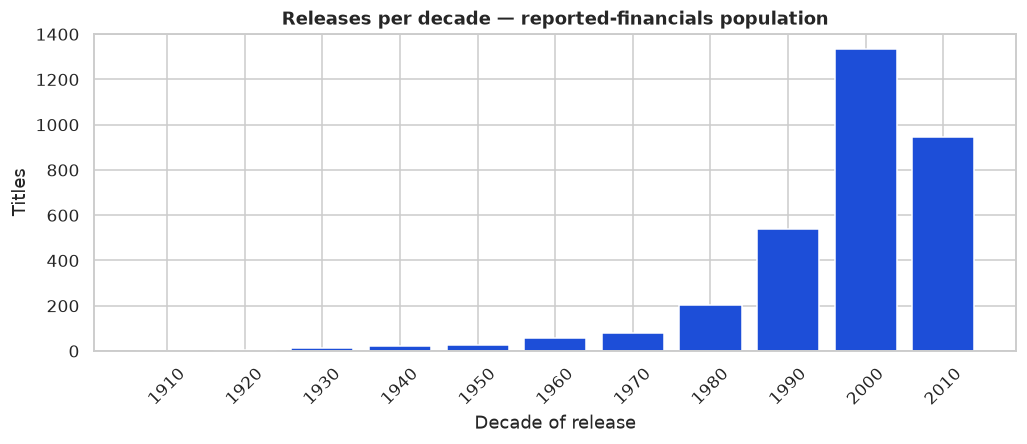

Release year range: 1916–2016


In [13]:
temporal['release_year'] = pd.to_datetime(temporal['release_date'], errors='coerce').dt.year
decade = (temporal['release_year'] // 10 * 10).astype('Int64')
decade_counts = decade.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.bar(decade_counts.index.astype(str), decade_counts.values, color='#1d4ed8')
ax.set_title('Releases per decade — reported-financials population')
ax.set_xlabel('Decade of release'); ax.set_ylabel('Titles')
plt.xticks(rotation=45)
plt.tight_layout(); plt.show()
print(f'Release year range: {int(temporal["release_year"].min())}–{int(temporal["release_year"].max())}')

## 10. Selection audit and handoff

The primary analysis uses positive, finite reported budget and revenue. The $10K subset is a sensitivity scenario only. The table reconciles the populations; it does not classify every excluded observation as erroneous.

In [14]:
funnel = pd.DataFrame({
    'Population': [
        'Raw source files',
        'Primary: positive finite budget and revenue',
        'Sensitivity: both budget and revenue strictly > $10K',
    ],
    'Rule': [
        'All merged records',
        'Retain reported positive financial values',
        'Optional scale restriction; not an error label',
    ],
    'Rows': [len(df_raw), len(df_reported), len(df_floor_sensitivity)],
    'Difference from previous': [None, len(df_raw) - len(df_reported), len(df_reported) - len(df_floor_sensitivity)],
})
print(funnel.to_string(index=False))
print(f'\nPrimary analysis population: {len(df_reported):,} rows; '
      f'{int(df_reported["target_nominal"].sum()):,} nominal gross-above-budget proxies.')
print('The optional threshold subset is reported for sensitivity only; do not name it a cleaned/canonical dataset.')

                                          Population                                           Rule  Rows  Difference from previous
                                    Raw source files                             All merged records  4803                       NaN
         Primary: positive finite budget and revenue      Retain reported positive financial values  3229                  1,574.00
Sensitivity: both budget and revenue strictly > $10K Optional scale restriction; not an error label  3203                     26.00

Primary analysis population: 3,229 rows; 2,438 nominal gross-above-budget proxies.
The optional threshold subset is reported for sensitivity only; do not name it a cleaned/canonical dataset.


### Findings and limits carried into later work

* **Merge:** 4,803 rows and 22 unique columns, with one-to-one keys and duplicate-title agreement verified.
* **Primary population:** 3,229 records with positive finite reported budget and revenue. The 1,574 remaining rows have at least one non-positive or unavailable financial value; their commercial outcome is unknown from these files.
* **Target proxies:** on the primary population, `revenue > budget` is 2,438/3,229 (75.50%); `revenue >= 2 × budget` is 1,809/3,229 (56.02%), and the strict `revenue > 2 × budget` is 1,804/3,229 (55.87%). These are gross-to-budget labels, not verified net-profit outcomes.
* **Scale sensitivity:** the strict >$10K rule excludes 26 records, including 16 nominal gross-at/below-budget and 10 above-budget. The data alone do not establish that the removed values are corrupt.
* **Distributions:** budget and revenue are right-skewed; report raw and log views. `log1p` reduces revenue skew but overshoots budget skew negative on the primary set, so it is a candidate transform to evaluate—not an assumed fix. The raw runtime median (>0) is 104 minutes; the reported-financials median is shown above.
* **Associations:** correlation is descriptive. Leakage classification requires feature-time provenance; a high correlation is not the definition of leakage.
* **Seasonality:** monthly means/medians are descriptive across a long historical window and should not be interpreted causally without year-aware analysis.

**Handoff gate:** freeze the target proxy and population only after reviewing these caveats. Before model training, split the raw rows first and fit every learned preprocessing step on training data only; use group- or time-aware validation if the prediction claim requires it.